<a href="https://colab.research.google.com/github/katheasanandres/BEMSS-CSE315-DATA-SCIENCE-Final-Project-/blob/main/BEMSS_CSE315_DATA_SCIENCE_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 1: Preprocessing (E-Commerce, Olist)
Source: https://www.kaggle.com/olistbr/brazilian-ecommerce

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Load Dataset

In [2]:
# Download with kagglehub (needs Kaggle login in Colab)
!pip -q install kagglehub
import kagglehub
DATA_DIR = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print(DATA_DIR)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
/kaggle/input/brazilian-ecommerce


In [3]:
import os, glob
import numpy as np
import pandas as pd

files = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
tables = {os.path.basename(f).replace(".csv", ""): pd.read_csv(f) for f in files}

overview = pd.DataFrame([(n, d.shape[0], d.shape[1]) for n, d in tables.items()],
                        columns=["table", "rows", "columns"])
print(overview)

                               table     rows  columns
0            olist_customers_dataset    99441        5
1          olist_geolocation_dataset  1000163        5
2          olist_order_items_dataset   112650        7
3       olist_order_payments_dataset   103886        5
4        olist_order_reviews_dataset    99224        7
5               olist_orders_dataset    99441        8
6             olist_products_dataset    32951        9
7              olist_sellers_dataset     3095        4
8  product_category_name_translation       71        2


## Set Data Dictionary Skeleton

In [4]:
rows = []
for name, df_ in tables.items():
    for col in df_.columns:
        rows.append({
            "table": name, "column": col, "dtype": str(df_[col].dtype),
            "non_null": int(df_[col].notna().sum()),
            "missing_pct": round(df_[col].isna().mean() * 100, 2),
            "n_unique": int(df_[col].nunique()),
            "example": df_[col].dropna().iloc[0] if df_[col].notna().any() else None,
            "description": "",
        })
data_dictionary = pd.DataFrame(rows)
data_dictionary.to_csv("data_dictionary_draft.csv", index=False)

# Columns shared by more than one table = candidate join keys
from collections import defaultdict
col_to_tables = defaultdict(list)
for n, d in tables.items():
    for c in d.columns:
        col_to_tables[c].append(n)
for c, t in col_to_tables.items():
    if len(t) > 1:
        print(c, "->", t)

customer_id -> ['olist_customers_dataset', 'olist_orders_dataset']
order_id -> ['olist_order_items_dataset', 'olist_order_payments_dataset', 'olist_order_reviews_dataset', 'olist_orders_dataset']
product_id -> ['olist_order_items_dataset', 'olist_products_dataset']
seller_id -> ['olist_order_items_dataset', 'olist_sellers_dataset']
product_category_name -> ['olist_products_dataset', 'product_category_name_translation']


## Cleaning and Missing Values

In [5]:
# ---- Team decisions ----
KEEP_STATUS = ["delivered"]   # H1 needs a delivery date
LOW_REVIEW_MAX = 2            # review score of 2 or below counts as low

orders    = tables["olist_orders_dataset"].copy()
items     = tables["olist_order_items_dataset"].copy()
payments  = tables["olist_order_payments_dataset"].copy()
reviews   = tables["olist_order_reviews_dataset"].copy()
customers = tables["olist_customers_dataset"].copy()
products  = tables["olist_products_dataset"].copy()

# Text -> datetime
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"], errors="coerce")

# EDA: statuses and where delivery dates are missing
print(orders["order_status"].value_counts())
print(orders.groupby("order_status")["order_delivered_customer_date"].apply(lambda s: s.isna().sum()))

orders = orders[orders["order_status"].isin(KEEP_STATUS)].copy()
print("Delivered but no delivery date:", orders["order_delivered_customer_date"].isna().sum())
orders = orders.dropna(subset=["order_delivered_customer_date"])

# Products: missing category -> "unknown", missing size/weight -> median
products["product_category_name"] = products["product_category_name"].fillna("unknown")
for c in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products[c] = products[c].fillna(products[c].median())

# Reviews: keep the latest review per order
reviews = (reviews.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last"))

for name, d in [("orders", orders), ("items", items), ("payments", payments),
                ("reviews", reviews), ("customers", customers)]:
    print(name, "duplicate rows:", d.duplicated().sum())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64
Delivered but no delivery date: 8
orders duplicate rows: 0
items duplicate rows: 0
payments duplicate rows: 0
reviews duplicate rows: 0
customers duplicate rows: 0


## Integration

In [6]:
items_agg = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"), n_sellers=("seller_id", "nunique"),
    total_price=("price", "sum"), total_freight=("freight_value", "sum")).reset_index()

main_pay = (payments.sort_values("payment_value", ascending=False)
                    .drop_duplicates("order_id")[["order_id", "payment_type"]])
pay_agg = payments.groupby("order_id").agg(
    total_payment=("payment_value", "sum"),
    max_installments=("payment_installments", "max")).reset_index().merge(main_pay, on="order_id")

df = (orders
      .merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
      .merge(items_agg, on="order_id", how="left")
      .merge(pay_agg, on="order_id", how="left")
      .merge(reviews[["order_id", "review_score"]], on="order_id", how="inner"))  # drops orders with no review

print(df.shape, "| unique orders:", df["order_id"].nunique())   # both numbers must match

# One order has no payment record: drop it before building anything from payments
print("Orders without payment record:", df["total_payment"].isna().sum())
df = df.dropna(subset=["total_payment"])

(95824, 18) | unique orders: 95824
Orders without payment record: 1


## Transformation

In [7]:
df["delivery_days"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.days
df["delay_days"]    = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.days
df["is_late"]       = (df["delay_days"] > 0).astype(int)                                  # H1
df["freight_ratio"] = np.where(df["total_price"] > 0, df["total_freight"] / df["total_price"], np.nan)  # H2
df["low_review"]    = (df["review_score"] <= LOW_REVIEW_MAX).astype(int)                  # Phase 2 target

df = pd.get_dummies(df, columns=["payment_type"], prefix="pay", drop_first=True)         # boleto = baseline

## Customer table & Reduction

In [8]:
cust = df.groupby("customer_unique_id").agg(
    n_orders=("order_id", "nunique"), total_spend=("total_payment", "sum")).reset_index()
cust["avg_order_value"] = cust["total_spend"] / cust["n_orders"]

drop_cols = ["order_status", "order_approved_at", "order_delivered_carrier_date"]
df_model = df.drop(columns=[c for c in drop_cols if c in df.columns])
print(df_model.isna().sum())

df_model.to_csv("orders_clean.csv", index=False)
cust.to_csv("customers_clean.csv", index=False)
print(df_model.shape, cust.shape)

order_id                         0
customer_id                      0
order_purchase_timestamp         0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_unique_id               0
customer_state                   0
n_items                          0
n_sellers                        0
total_price                      0
total_freight                    0
total_payment                    0
max_installments                 0
review_score                     0
delivery_days                    0
delay_days                       0
is_late                          0
freight_ratio                    0
low_review                       0
pay_credit_card                  0
pay_debit_card                   0
pay_voucher                      0
dtype: int64
(95823, 22) (92746, 4)


## EDA and first look at the hypotheses

In [9]:
print(df_model[["delivery_days", "delay_days", "total_price", "total_freight",
                "freight_ratio", "review_score", "low_review"]].describe())
print(df_model["low_review"].value_counts(normalize=True))

# H1
print(df_model["is_late"].value_counts())
print(df_model.groupby("is_late")[["review_score", "low_review"]].mean())

# H2
df_model["freight_group"] = pd.qcut(df_model["freight_ratio"], 4, duplicates="drop")
print(df_model.groupby("freight_group", observed=True)[["review_score", "low_review"]].mean())

# H3
print(cust.describe())
print(cust["n_orders"].value_counts().head())
print("Customers with zero spend:", (cust["total_spend"] == 0).sum())

       delivery_days    delay_days   total_price  total_freight  \
count   95823.000000  95823.000000  95823.000000   95823.000000   
mean       12.051835    -11.913570    136.800241      22.763026   
std         9.465126     10.110605    207.789369      21.522731   
min         0.000000   -147.000000      0.850000       0.000000   
25%         6.000000    -17.000000     45.900000      13.840000   
50%        10.000000    -12.000000     86.250000      17.160000   
75%        15.000000     -7.000000    149.900000      23.990000   
max       208.000000    188.000000  13440.000000    1794.960000   

       freight_ratio  review_score    low_review  
count   95823.000000  95823.000000  95823.000000  
mean        0.308450      4.155912      0.128059  
std         0.311787      1.284777      0.334157  
min         0.000000      1.000000      0.000000  
25%         0.132028      4.000000      0.000000  
50%         0.224374      5.000000      0.000000  
75%         0.380567      5.000000     

# Phase 2: Model Development

### Load Data and Choose Features

In [10]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

df = pd.read_csv("orders_clean.csv")

pay_cols = [c for c in df.columns if c.startswith("pay_")]
FEATURES = ["delivery_days", "delay_days", "is_late", "freight_ratio", "total_price",
            "total_freight", "n_items", "n_sellers", "total_payment", "max_installments"] + pay_cols
TARGET = "low_review"

X = df[FEATURES].astype(float)
y = df[TARGET].astype(int)
print(X.shape, "| missing values:", int(X.isna().sum().sum()))
print(y.value_counts(normalize=True))

(95823, 13) | missing values: 0
low_review
0    0.871941
1    0.128059
Name: proportion, dtype: float64


## Train / Validation / Test Split

In [11]:
SEED = 42

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(len(X_train), len(X_val), len(X_test))

# Logistic regression needs inputs on a similar scale. Fit the scaler on train only.
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_val, Xs_test = (scaler.transform(a) for a in (X_train, X_val, X_test))

57493 19165 19165


## Experiment Log

In [12]:
experiment_log = []
fitted = {}

def score(y_true, pred, proba):
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, proba)}

def run_experiment(model_name, model, params, Xtr, Xva):
    model.fit(Xtr, y_train)
    pred = model.predict(Xva)
    proba = model.predict_proba(Xva)[:, 1]
    run_id = len(experiment_log) + 1
    experiment_log.append({"run_id": run_id, "model": model_name, "split": "validation",
                           **params, "train_rows": len(y_train), "eval_rows": len(y_val),
                           **score(y_val, pred, proba)})
    fitted[run_id] = model

## Logistic Regression Runs

In [13]:
for cw in [None, "balanced"]:
    for C in [0.01, 0.1, 1, 10]:
        m = LogisticRegression(C=C, class_weight=cw, max_iter=1000, random_state=SEED)
        run_experiment("logistic_regression", m, {"C": C, "class_weight": str(cw)}, Xs_train, Xs_val)

pd.DataFrame(experiment_log)

,run_id,model,split,C,class_weight,train_rows,eval_rows,accuracy,precision,recall,f1,roc_auc
0,1,logistic_regression,validation,0.01,None,57493,19165,0.891678,0.660457,0.317719,0.429043,0.745351
1,2,logistic_regression,validation,0.10,None,57493,19165,0.891469,0.657696,0.318534,0.429199,0.745217
2,3,logistic_regression,validation,1.00,None,57493,19165,0.891521,0.657983,0.318941,0.429630,0.745194
3,4,logistic_regression,validation,10.00,None,57493,19165,0.891521,0.657983,0.318941,0.429630,0.745193
4,5,logistic_regression,validation,0.01,balanced,57493,19165,0.839134,0.398840,0.504277,0.445404,0.746640
5,6,logistic_regression,validation,0.10,balanced,57493,19165,0.838769,0.398074,0.505092,0.445242,0.746617
6,7,logistic_regression,validation,1.00,balanced,57493,19165,0.838716,0.397946,0.505092,0.445162,0.746614
7,8,logistic_regression,validation,10.00,balanced,57493,19165,0.838664,0.397818,0.505092,0.445083,0.746613


## Decision Tree Runs

In [14]:
for cw in [None, "balanced"]:
    for depth in [3, 5, 8]:
        m = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, class_weight=cw, random_state=SEED)
        run_experiment("decision_tree", m, {"max_depth": depth, "min_samples_leaf": 50, "class_weight": str(cw)}, X_train, X_val)

log = pd.DataFrame(experiment_log)
log.sort_values("f1", ascending=False)

,run_id,model,split,C,class_weight,train_rows,eval_rows,accuracy,precision,recall,f1,roc_auc,max_depth,min_samples_leaf
12,13,decision_tree,validation,NaN,balanced,57493,19165,0.843256,0.411194,0.517719,0.458348,0.741729,5.0,50.0
4,5,logistic_regression,validation,0.01,balanced,57493,19165,0.839134,0.398840,0.504277,0.445404,0.746640,NaN,NaN
5,6,logistic_regression,validation,0.10,balanced,57493,19165,0.838769,0.398074,0.505092,0.445242,0.746617,NaN,NaN
6,7,logistic_regression,validation,1.00,balanced,57493,19165,0.838716,0.397946,0.505092,0.445162,0.746614,NaN,NaN
7,8,logistic_regression,validation,10.00,balanced,57493,19165,0.838664,0.397818,0.505092,0.445083,0.746613,NaN,NaN
3,4,logistic_regression,validation,10.00,None,57493,19165,0.891521,0.657983,0.318941,0.429630,0.745193,NaN,NaN
2,3,logistic_regression,validation,1.00,None,57493,19165,0.891521,0.657983,0.318941,0.429630,0.745194,NaN,NaN
1,2,logistic_regression,validation,0.10,None,57493,19165,0.891469,0.657696,0.318534,0.429199,0.745217,NaN,NaN
0,1,logistic_regression,validation,0.01,None,57493,19165,0.891678,0.660457,0.317719,0.429043,0.745351,NaN,NaN
9,10,decision_tree,validation,NaN,None,57493,19165,0.896895,0.749220,0.293279,0.421546,0.742272,5.0,50.0


## Pick the Best Run of Each Model (by validation F1)

In [15]:
SELECT_BY = "f1"
best = {}
for name in ["logistic_regression", "decision_tree"]:
    sub = log[(log["model"] == name) & (log["split"] == "validation")]
    best[name] = int(sub.sort_values(SELECT_BY, ascending=False).iloc[0]["run_id"])
print(best)
log[log["run_id"].isin(best.values())]

{'logistic_regression': 5, 'decision_tree': 13}


,run_id,model,split,C,class_weight,train_rows,eval_rows,accuracy,precision,recall,f1,roc_auc,max_depth,min_samples_leaf
4,5,logistic_regression,validation,0.01,balanced,57493,19165,0.839134,0.398840,0.504277,0.445404,0.746640,NaN,NaN
12,13,decision_tree,validation,NaN,balanced,57493,19165,0.843256,0.411194,0.517719,0.458348,0.741729,5.0,50.0


## Test Set Final Check (done once)

In [16]:
test_inputs = {"logistic_regression": Xs_test, "decision_tree": X_test}
cms = {}
for name, run_id in best.items():
    model = fitted[run_id]
    pred = model.predict(test_inputs[name])
    proba = model.predict_proba(test_inputs[name])[:, 1]
    params = {k: v for k, v in log[log["run_id"] == run_id].iloc[0].items()
              if k in ("C", "max_depth", "min_samples_leaf", "class_weight") and pd.notna(v)}
    experiment_log.append({"run_id": len(experiment_log) + 1, "model": name, "split": "test",
                           "source_run": run_id, **params, "train_rows": len(y_train),
                           "eval_rows": len(y_test), **score(y_test, pred, proba)})
    cms[name] = confusion_matrix(y_test, pred)

log = pd.DataFrame(experiment_log)
log[log["split"] == "test"]

,run_id,model,split,C,class_weight,train_rows,eval_rows,accuracy,precision,recall,f1,roc_auc,max_depth,min_samples_leaf,source_run
14,15,logistic_regression,test,0.01,balanced,57493,19165,0.838821,0.398139,0.505705,0.445521,0.750704,NaN,NaN,5.0
15,16,decision_tree,test,NaN,balanced,57493,19165,0.841064,0.405067,0.514670,0.453338,0.746496,5.0,50.0,13.0


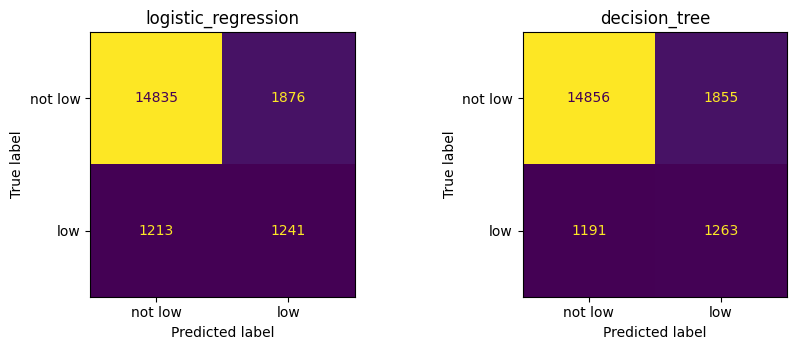

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (name, cm) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["not low", "low"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## What the Models Learned

is_late             0.498950
delivery_days       0.395488
n_items             0.322423
n_sellers           0.196216
max_installments    0.050911
pay_voucher         0.033257
total_freight      -0.024096
freight_ratio       0.017977
delay_days          0.014724
total_price         0.014048
total_payment       0.011172
pay_credit_card     0.007086
pay_debit_card      0.005350
dtype: float64
delay_days          0.687759
n_items             0.208041
delivery_days       0.074661
n_sellers           0.018826
total_freight       0.005502
max_installments    0.002586
freight_ratio       0.001433
pay_credit_card     0.001190
is_late             0.000000
total_price         0.000000
total_payment       0.000000
pay_debit_card      0.000000
pay_voucher         0.000000
dtype: float64


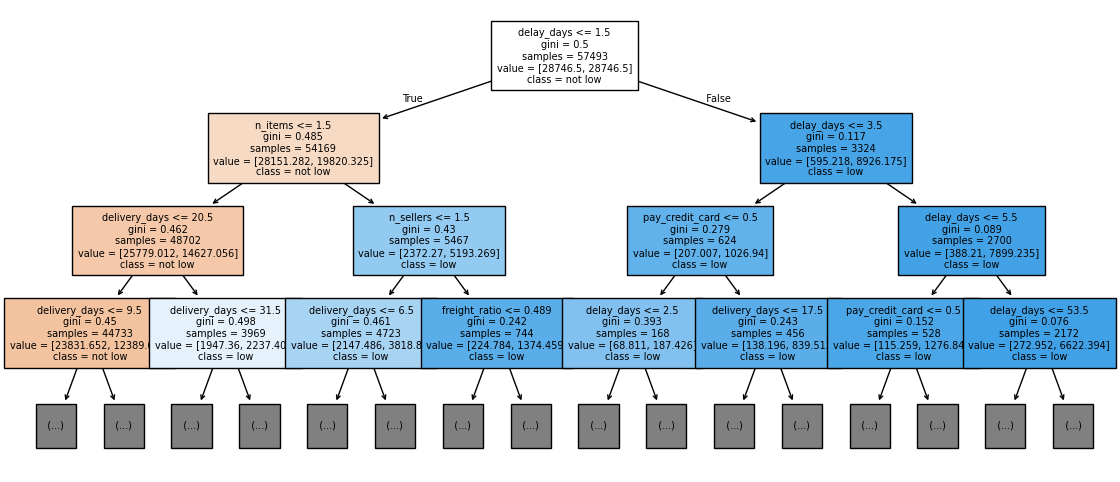

In [18]:
lr = fitted[best["logistic_regression"]]
coefs = pd.Series(lr.coef_[0], index=FEATURES).sort_values(key=abs, ascending=False)
print(coefs)

tree = fitted[best["decision_tree"]]
imp = pd.Series(tree.feature_importances_, index=FEATURES).sort_values(ascending=False)
print(imp)

plt.figure(figsize=(14, 6))
plot_tree(tree, feature_names=FEATURES, class_names=["not low", "low"], max_depth=3, filled=True, fontsize=7)
plt.show()

## Model Artifact and Log Saving

In [19]:
log.to_csv("model_experiment_log.csv", index=False)

artifacts = {"features": FEATURES, "seed": SEED, "scaler": scaler,
             "logistic_regression": fitted[best["logistic_regression"]],
             "decision_tree": fitted[best["decision_tree"]]}
with open("model_artifacts.pkl", "wb") as f:
    pickle.dump(artifacts, f)
print("saved", len(log), "log rows")

saved 16 log rows


## Load Customers and Prepare Spend

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = globals().get("SEED", 42)
if "experiment_log" not in globals():
    experiment_log = []

cust = pd.read_csv("customers_clean.csv")
print(cust.shape)
print(cust["total_spend"].describe())

cust["log_spend"] = np.log1p(cust["total_spend"])
km_scaler = StandardScaler().fit(cust[["log_spend"]])
Z = km_scaler.transform(cust[["log_spend"]])

(92746, 4)
count    92746.000000
mean       164.887458
std        224.993605
min          9.590000
25%         63.000000
50%        107.780000
75%        182.147500
max      13664.080000
Name: total_spend, dtype: float64


## k-Means runs, k = 2 to 8

In [21]:
km_models = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = km.fit_predict(Z)
    sil = silhouette_score(Z, labels, sample_size=10000, random_state=SEED)
    run_id = len(experiment_log) + 1
    experiment_log.append({"run_id": run_id, "model": "kmeans", "split": "all customers", "k": k,
                           "n_init": 10, "scaling": "log1p + standardize",
                           "train_rows": len(Z), "inertia": km.inertia_, "silhouette": sil})
    km_models[k] = (run_id, km, labels)

km_log = pd.DataFrame([r for r in experiment_log if r["model"] == "kmeans"])
km_log[["run_id", "k", "inertia", "silhouette"]]

,run_id,k,inertia,silhouette
0,17,2,34792.671247,0.553543
1,18,3,17771.930040,0.546341
2,19,4,10843.143745,0.536548
3,20,5,7174.460431,0.526475
4,21,6,5106.473321,0.534464
5,22,7,3953.118346,0.515440
6,23,8,3132.228478,0.517021


## Elbow and Silhouette Plots

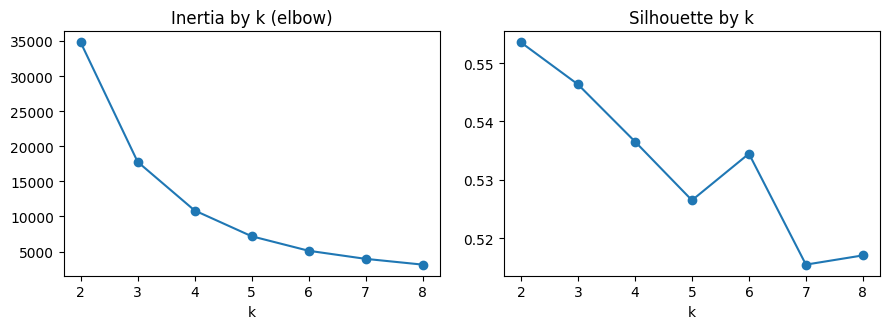

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(km_log["k"], km_log["inertia"], marker="o"); axes[0].set_title("Inertia by k (elbow)"); axes[0].set_xlabel("k")
axes[1].plot(km_log["k"], km_log["silhouette"], marker="o"); axes[1].set_title("Silhouette by k"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

## Choose k and Describe Groups

In [23]:
K_CHOICE = None   # team decision: None = highest silhouette, or type a number from 2 to 8
k_final = int(km_log.sort_values("silhouette", ascending=False).iloc[0]["k"]) if K_CHOICE is None else K_CHOICE
run_id_final, km_final, labels_final = km_models[k_final]
print("chosen k:", k_final, "| run_id:", run_id_final)

cust["group"] = labels_final
order = cust.groupby("group")["total_spend"].mean().sort_values().index
rank = {g: i + 1 for i, g in enumerate(order)}
cust["spend_group"] = cust["group"].map(rank)

profile = cust.groupby("spend_group").agg(
    customers=("customer_unique_id", "count"),
    mean_spend=("total_spend", "mean"), median_spend=("total_spend", "median"),
    min_spend=("total_spend", "min"), max_spend=("total_spend", "max"),
    mean_orders=("n_orders", "mean"))
profile["share_pct"] = (profile["customers"] / len(cust) * 100).round(1)
profile.round(2)

chosen k: 2 | run_id: 17


,customers,mean_spend,median_spend,min_spend,max_spend,mean_orders,share_pct
spend_group,,,,,,,
1,51927,68.97,67.02,9.59,121.33,1.01,56.0
2,40819,286.90,196.57,121.34,13664.08,1.06,44.0


## Spend by Group Chart

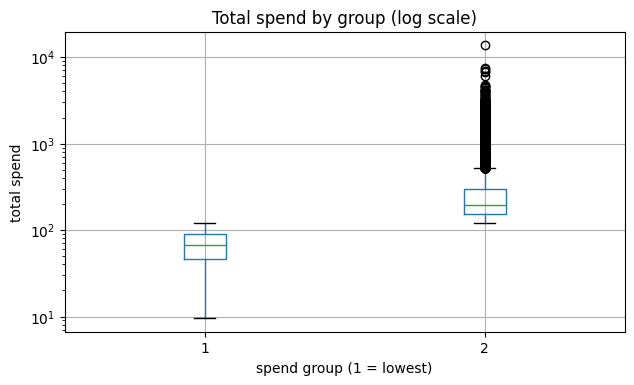

In [24]:
cust.boxplot(column="total_spend", by="spend_group", figsize=(7, 4))
plt.yscale("log"); plt.suptitle(""); plt.title("Total spend by group (log scale)")
plt.xlabel("spend group (1 = lowest)"); plt.ylabel("total spend"); plt.show()

## Log, Labels, and Artifact Saving

In [25]:
log = pd.DataFrame(experiment_log)
log.to_csv("model_experiment_log.csv", index=False)

cust[["customer_unique_id", "total_spend", "n_orders", "spend_group"]].to_csv("customers_clustered.csv", index=False)

artifacts = globals().get("artifacts", {})
artifacts.update({"kmeans": km_final, "kmeans_scaler": km_scaler, "kmeans_k": k_final,
                  "kmeans_group_rank": rank})
with open("model_artifacts.pkl", "wb") as f:
    pickle.dump(artifacts, f)
print("saved", len(log), "log rows")

saved 23 log rows


# Phase 3: Visualization Portfolio

## Setup

In [26]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.0)
BLUE, ORANGE, GRAY = "#1F3A5F", "#D9822B", "#9AA5B1"

if "df_model" not in globals():
    df_model = pd.read_csv("orders_clean.csv")

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def rate_bar(ax, labels, values, colors, ylabel):
    bars = ax.bar(labels, values, color=colors)
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v + max(values) * 0.02, f"{v:.1f}%", ha="center", fontweight="bold")
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)

def roc_panel(ax):
    for (name, run_id), color in zip(best.items(), [BLUE, ORANGE]):
        proba = fitted[run_id].predict_proba(test_inputs[name])[:, 1]
        fpr, tpr, _ = roc_curve(y_test, proba)
        ax.plot(fpr, tpr, color=color, lw=2, label=f"{name.replace('_', ' ')} (AUC {roc_auc_score(y_test, proba):.3f})")
    ax.plot([0, 1], [0, 1], "--", color=GRAY, label="random guess")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(loc="lower right", fontsize=8)

## Chart 1: Late Delivery and Low Reviews (H1)

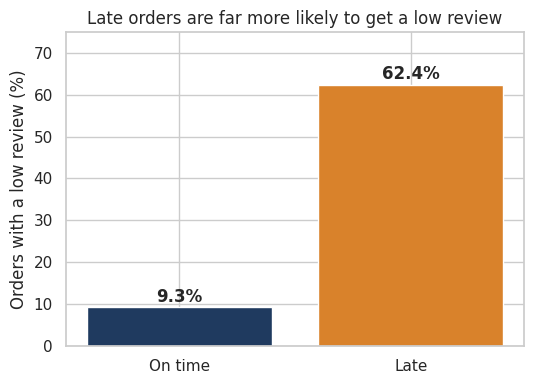

In [27]:
rate = df_model.groupby("is_late")["low_review"].mean() * 100
fig, ax = plt.subplots(figsize=(5.5, 4))
rate_bar(ax, ["On time", "Late"], [rate.loc[0], rate.loc[1]], [BLUE, ORANGE], "Orders with a low review (%)")
ax.set_title("Late orders are far more likely to get a low review")
save("01_late_vs_low_review")

## Chart 2: How Early or Late Orders Arrive

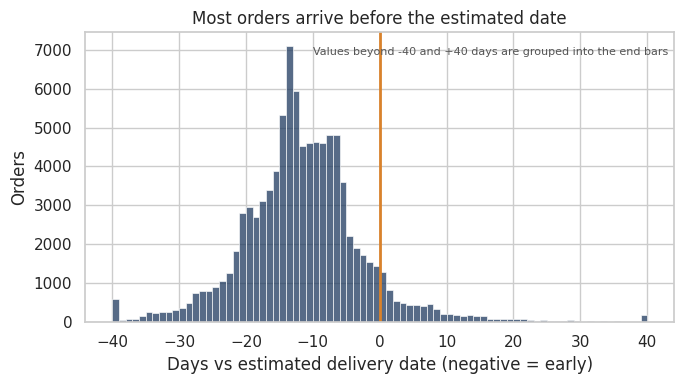

In [28]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df_model["delay_days"].clip(-40, 40), bins=80, color=BLUE, ax=ax)
ax.axvline(0, color=ORANGE, lw=2)
ax.set_xlabel("Days vs estimated delivery date (negative = early)")
ax.set_ylabel("Orders"); ax.set_title("Most orders arrive before the estimated date")
ax.text(0.99, 0.95, "Values beyond -40 and +40 days are grouped into the end bars",
        transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#555555")
save("02_delivery_delay_distribution")

## Chart 3: Freight Share and Low Reviews (H2)

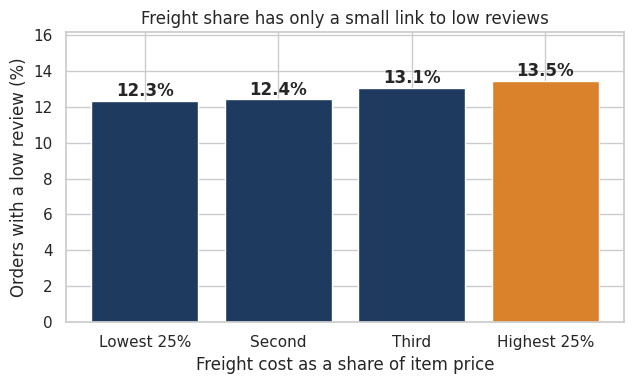

In [29]:
fg = pd.qcut(df_model["freight_ratio"], 4, labels=["Lowest 25%", "Second", "Third", "Highest 25%"])
r = df_model.groupby(fg, observed=True)["low_review"].mean() * 100
fig, ax = plt.subplots(figsize=(6.5, 4))
rate_bar(ax, list(r.index), list(r.values), [BLUE, BLUE, BLUE, ORANGE], "Orders with a low review (%)")
ax.set_xlabel("Freight cost as a share of item price"); ax.set_title("Freight share has only a small link to low reviews")
save("03_freight_share_vs_low_review")

## Chart 4: Correlation Heatmap

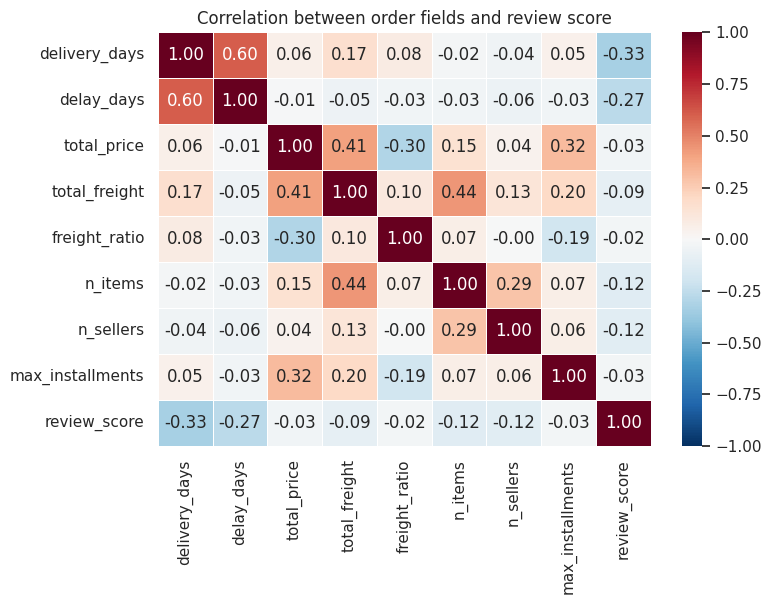

In [30]:
cols = ["delivery_days", "delay_days", "total_price", "total_freight", "freight_ratio",
        "n_items", "n_sellers", "max_installments", "review_score"]
corr = df_model[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Correlation between order fields and review score")
save("04_correlation_heatmap")

## Chart 5: ROC Curves (test set)

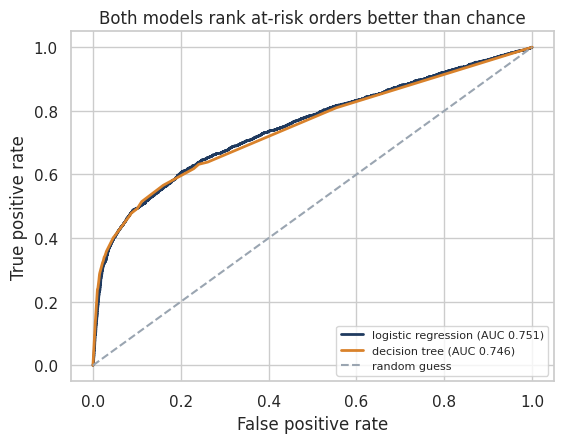

In [31]:
fig, ax = plt.subplots(figsize=(5.8, 4.6))
roc_panel(ax)
ax.set_title("Both models rank at-risk orders better than chance")
save("05_roc_curves")

## Chart 6: Confusion Matrices (test set)

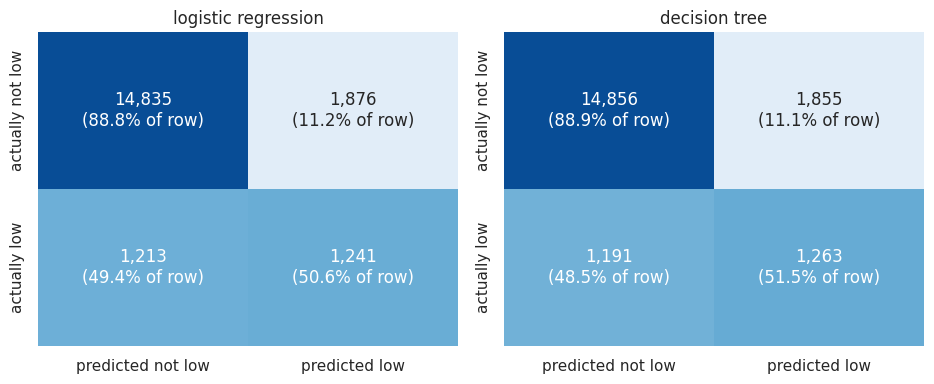

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, (name, cm) in zip(axes, cms.items()):
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    labels = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.1f}% of row)" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=labels, fmt="", cmap="Blues", cbar=False, vmin=0, vmax=100,
                xticklabels=["predicted not low", "predicted low"], yticklabels=["actually not low", "actually low"], ax=ax)
    ax.set_title(name.replace("_", " "))
save("06_confusion_matrices")

## Chart 7: What Drives Low Reviews

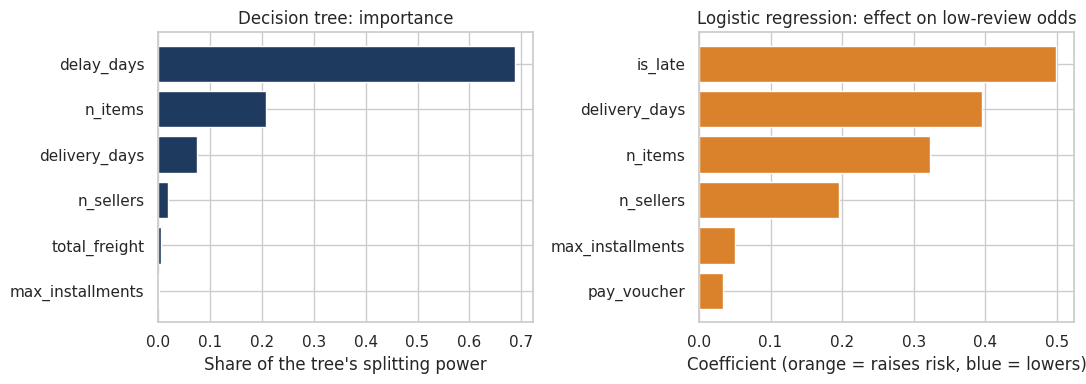

In [33]:
imp = pd.Series(fitted[best["decision_tree"]].feature_importances_, index=FEATURES).sort_values(ascending=False).head(6)
coefs = pd.Series(fitted[best["logistic_regression"]].coef_[0], index=FEATURES)
coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).head(6).index)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(imp.index, imp.values, color=BLUE); axes[0].invert_yaxis()
axes[0].set_title("Decision tree: importance"); axes[0].set_xlabel("Share of the tree's splitting power")
axes[1].barh(coefs.index, coefs.values, color=[ORANGE if v > 0 else BLUE for v in coefs.values]); axes[1].invert_yaxis()
axes[1].set_title("Logistic regression: effect on low-review odds"); axes[1].set_xlabel("Coefficient (orange = raises risk, blue = lowers)")
save("07_drivers_of_low_reviews")

## Chart 8: Customer Spend Groups (k = 2)

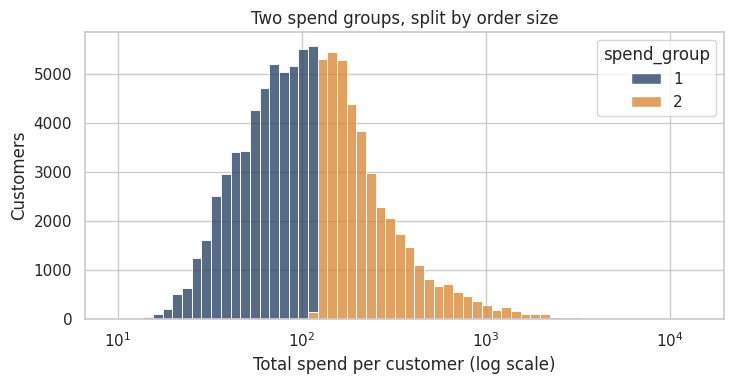

In [34]:
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.histplot(data=cust, x="total_spend", hue="spend_group", log_scale=True, bins=60, multiple="stack",
             palette={1: BLUE, 2: ORANGE}, ax=ax)
ax.set_xlabel("Total spend per customer (log scale)"); ax.set_ylabel("Customers")
ax.set_title("Two spend groups, split by order size")
save("08_spend_groups")
ax.get_legend().set_title("Spend group (1 = lower)")

## Chart 9: One-page Dashboard

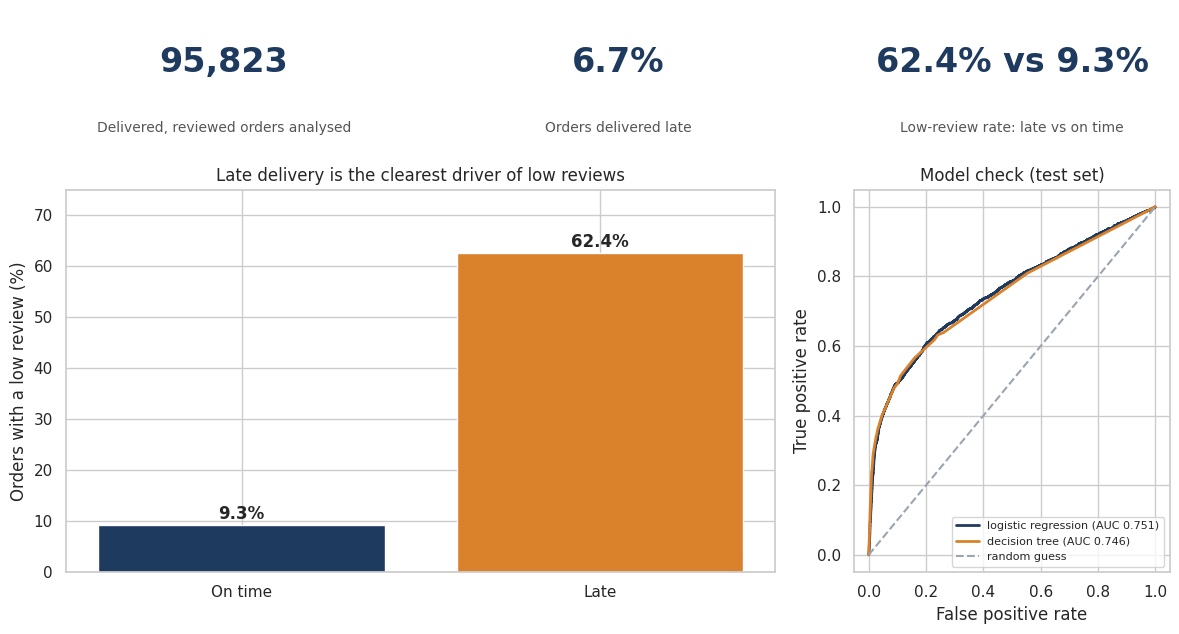

In [35]:
rate_on, rate_late = rate.loc[0], rate.loc[1]
fig = plt.figure(figsize=(12, 6.5))
gs = fig.add_gridspec(2, 3, height_ratios=[0.8, 2.2])
kpis = [("Delivered, reviewed orders analysed", f"{len(df_model):,}"),
        ("Orders delivered late", f"{df_model['is_late'].mean() * 100:.1f}%"),
        ("Low-review rate: late vs on time", f"{rate_late:.1f}% vs {rate_on:.1f}%")]
for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=24, fontweight="bold", color=BLUE)
    ax.text(0.5, 0.15, label, ha="center", va="center", fontsize=10, color="#555555")
ax1 = fig.add_subplot(gs[1, :2])
rate_bar(ax1, ["On time", "Late"], [rate_on, rate_late], [BLUE, ORANGE], "Orders with a low review (%)")
ax1.set_title("Late delivery is the clearest driver of low reviews")
ax2 = fig.add_subplot(gs[1, 2]); roc_panel(ax2); ax2.set_title("Model check (test set)")
save("09_dashboard")

## Zipping the Figures

In [36]:
import shutil
shutil.make_archive("figures", "zip", "figures")
print(sorted(os.listdir("figures")))

['01_late_vs_low_review.png', '02_delivery_delay_distribution.png', '03_freight_share_vs_low_review.png', '04_correlation_heatmap.png', '05_roc_curves.png', '06_confusion_matrices.png', '07_drivers_of_low_reviews.png', '08_spend_groups.png', '09_dashboard.png']
